# Nigeria economic indicators: exploratory analysis

This notebook explores the warehouse directly and goes a step further
than [the written report](../reports/nigeria_economic_findings.md): it
tests whether the series are suitable for the kind of regression people
usually reach for, and shows why the answer changes how the
relationships should be measured.

**What this notebook adds beyond the report**

1. The provenance and data-quality structure of the warehouse, queried
   rather than described.
2. Stationarity testing, and the spurious-regression trap it avoids.
3. The inflation / income relationship, estimated on a basis the data
   actually supports.
4. The within-zone spread in state demography, which the zone averages
   in the report hide.

**Prerequisites**: the database running, migrations applied, and both
connectors loaded. See the README.

## 1. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import text

from nigeria_economic_intelligence import analysis
from nigeria_economic_intelligence.database import engine

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "axes.axisbelow": True,
    "font.size": 10,
})

BLUE, ORANGE, RED, MUTED = "#2a78d6", "#eb6834", "#d03b3b", "#898781"

## 2. What is actually in the warehouse

Rather than trusting documentation, ask the database. This also shows
the point of the provenance schema: every observation knows its source,
its import batch, and whether it was measured or modelled.

In [2]:
inventory = pd.read_sql(text("""
    SELECT ds.source_code,
           ds.organization,
           count(*) AS observations,
           count(DISTINCT o.indicator_id) AS indicators,
           count(DISTINCT o.geography_id) AS geographies,
           min(o.period_start) AS earliest,
           max(o.period_end) AS latest
    FROM indicator_observations AS o
    JOIN data_sources AS ds ON ds.source_id = o.source_id
    GROUP BY ds.source_code, ds.organization
    ORDER BY observations DESC
"""), engine)

inventory

,source_code,organization,observations,indicators,geographies,earliest,latest
0,WORLDBANK_WDI,World Bank,486,14,1,1991-01-01,2025-12-31
1,HDX_COD_PS_NGA,UNFPA and United States Census Bureau,222,6,37,2022-01-01,2022-12-31
2,SYNTHETIC_DEMO,Internal test,2,1,1,2026-01-01,2026-02-28


Note the third row. The synthetic demo data is still present and still
clearly labelled as synthetic — it is never silently mixed into
analysis. Every query below filters to real sources.

In [3]:
quality = pd.read_sql(text("""
    SELECT i.domain,
           o.observation_status,
           count(*) AS observations
    FROM indicator_observations AS o
    JOIN indicators AS i ON i.indicator_id = o.indicator_id
    JOIN data_sources AS ds ON ds.source_id = o.source_id
    WHERE ds.source_code <> 'SYNTHETIC_DEMO'
    GROUP BY i.domain, o.observation_status
    ORDER BY i.domain, o.observation_status
"""), engine)

quality.pivot(
    index="domain", columns="observation_status", values="observations"
).fillna(0).astype(int)

observation_status,estimated,observed
domain,,
agriculture,0,35
demographics,222,35
economy,0,136
labour_market,245,0
prices,0,35


Every labour-market observation is `estimated`, not `observed`. That is
the ILO-modelled distinction, enforced in the data rather than left to a
footnote: a query can exclude modelled series without knowing which
indicator codes they are.

## 3. National series

Load the annual national indicators as a year-by-indicator frame.

In [4]:
national = analysis.load_indicators()
print(f"{national.shape[0]} years x {national.shape[1]} indicators")
national.tail(5).iloc[:, :6].round(2)

35 years x 14 indicators


code,NGA_AGRI_VALUE_ADDED,NGA_EMPLOYMENT_AGRICULTURE,NGA_EMPLOYMENT_INDUSTRY,NGA_EMPLOYMENT_SERVICES,NGA_GDP_GROWTH,NGA_GDP_PER_CAPITA
year,,,,,,
2021,29.39,37.27,15.59,47.14,1.11,2206.66
2022,28.55,35.25,16.82,47.93,4.32,2254.29
2023,27.72,34.70,16.82,48.47,3.32,2280.68
2024,25.87,34.10,16.84,49.06,4.07,2324.60
2025,22.98,33.53,17.01,49.46,4.01,2368.54


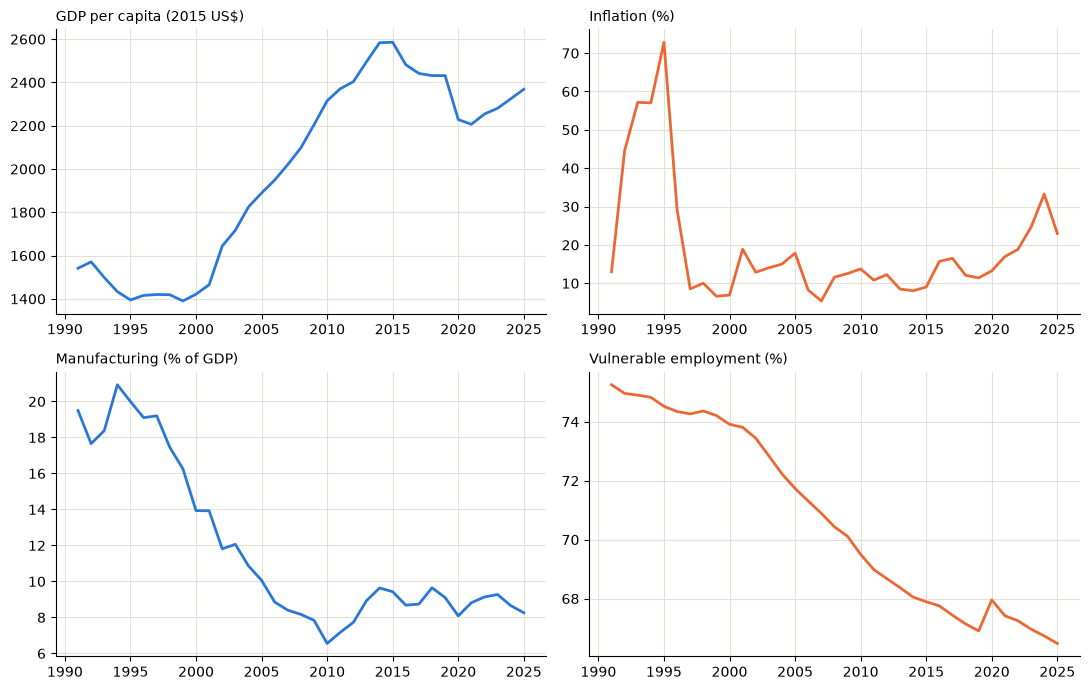

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

panels = [
    ("NGA_GDP_PER_CAPITA", "GDP per capita (2015 US$)", BLUE),
    ("NGA_INFLATION_CPI", "Inflation (%)", ORANGE),
    ("NGA_MANUF_VALUE_ADDED", "Manufacturing (% of GDP)", BLUE),
    ("NGA_VULNERABLE_EMPLOYMENT", "Vulnerable employment (%)", ORANGE),
]

for ax, (code_, label, colour) in zip(axes.ravel(), panels):
    series = national[code_].dropna()
    ax.plot(series.index, series.values, color=colour, linewidth=2)
    ax.set_title(label, fontsize=10, loc="left")

fig.tight_layout()
plt.show()

## 4. Are these series stationary?

Before correlating or regressing anything, test it. Most macroeconomic
level series trend, and regressing one trending series on another
produces a high R-squared that means nothing — the classic spurious
regression. The Augmented Dickey-Fuller test has a null hypothesis of a
unit root, so **p above 0.05 means we cannot reject non-stationarity**.

In [6]:
from statsmodels.tsa.stattools import adfuller

def adf_table(frame, codes):
    rows = []
    for code_ in codes:
        series = frame[code_].dropna()
        level = adfuller(series, autolag="AIC")
        diff = adfuller(series.diff().dropna(), autolag="AIC")
        rows.append({
            "indicator": code_.replace("NGA_", ""),
            "n": len(series),
            "level p": round(level[1], 3),
            "differenced p": round(diff[1], 4),
            "verdict": (
                "I(1): difference before use"
                if level[1] > 0.05 and diff[1] <= 0.05
                else "stationary in levels"
                if level[1] <= 0.05
                else "inconclusive"
            ),
        })
    return pd.DataFrame(rows).set_index("indicator")

adf_table(national, [
    "NGA_GDP_PER_CAPITA",
    "NGA_INFLATION_CPI",
    "NGA_MANUF_VALUE_ADDED",
    "NGA_VULNERABLE_EMPLOYMENT",
])

,n,level p,differenced p,verdict
indicator,,,,
GDP_PER_CAPITA,35,0.796,0.0235,I(1): difference before use
INFLATION_CPI,35,0.205,0.0069,I(1): difference before use
MANUF_VALUE_ADDED,35,0.482,0.0000,I(1): difference before use
VULNERABLE_EMPLOYMENT,35,0.894,0.0000,I(1): difference before use


All four are **I(1)**: non-stationary in levels, stationary once
differenced. So a regression of, say, per-capita income on manufacturing
share *in levels* would be spurious, however good its R-squared looked.

The practical consequence: work in growth rates and changes, not levels.
Note also that `n = 35` is small for time-series inference — ADF has low
power in short samples, so this is a reason for caution, not a licence
to proceed confidently.

## 5. Inflation and income growth

Now the relationship can be examined on a defensible basis. Per-capita
income enters as log-difference (a growth rate), which is stationary by
the test above.

In [7]:
growth = np.log(national["NGA_GDP_PER_CAPITA"].dropna()).diff() * 100
growth.name = "gdppc_growth"

paired = (
    growth.to_frame()
    .join(national["NGA_INFLATION_CPI"].rename("inflation"))
    .dropna()
)

print(f"n = {len(paired)}")
print(f"correlation = {paired.corr().iloc[0, 1]:.3f}")
paired.describe().round(2)

n = 34
correlation = -0.377


,gdppc_growth,inflation
count,34.00,34.00
mean,1.26,19.33
std,3.69,15.96
min,-8.71,5.39
25%,-0.32,10.20
50%,1.89,13.49
75%,3.48,18.87
max,11.52,72.84


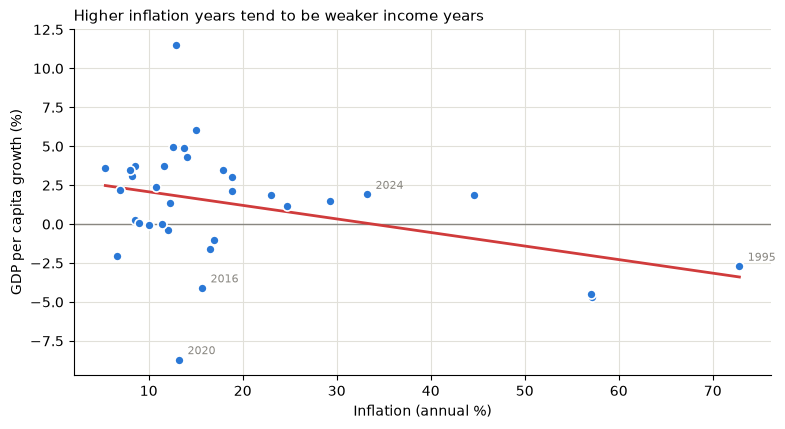

slope: -0.087 pp of per-capita growth per pp of inflation


In [8]:
fig, ax = plt.subplots()

ax.scatter(
    paired["inflation"], paired["gdppc_growth"],
    color=BLUE, s=42, edgecolor="white", linewidth=1.2, zorder=3,
)
ax.axhline(0, color=MUTED, linewidth=1)

slope, intercept = np.polyfit(
    paired["inflation"], paired["gdppc_growth"], 1
)
grid = np.linspace(paired["inflation"].min(), paired["inflation"].max(), 50)
ax.plot(grid, slope * grid + intercept, color=RED, linewidth=2, zorder=2)

for year in (1995, 2016, 2020, 2024):
    if year in paired.index:
        row = paired.loc[year]
        ax.annotate(
            str(year),
            (row["inflation"], row["gdppc_growth"]),
            xytext=(6, 4), textcoords="offset points",
            fontsize=8, color=MUTED,
        )

ax.set_xlabel("Inflation (annual %)")
ax.set_ylabel("GDP per capita growth (%)")
ax.set_title(
    "Higher inflation years tend to be weaker income years",
    loc="left", fontsize=11,
)
plt.show()

print(f"slope: {slope:.3f} pp of per-capita growth per pp of inflation")

In [9]:
import statsmodels.api as sm

model = sm.OLS(
    paired["gdppc_growth"],
    sm.add_constant(paired["inflation"]),
).fit()

print(model.summary().tables[1])
print(f"R-squared: {model.rsquared:.3f}   n = {int(model.nobs)}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9469      0.943      3.126      0.004       1.027       4.867
inflation     -0.0871      0.038     -2.303      0.028      -0.164      -0.010
R-squared: 0.142   n = 34


**How far this goes, and no further.** The association is negative and
modest. It is *not* evidence that inflation causes slower growth: with
n = 34, no controls, no lag structure and obvious reverse causality
(weak growth and currency pressure drive inflation in Nigeria at least
as plausibly as the reverse), this is a stylised fact to be explained,
not a result. Establishing direction would need an identification
strategy this dataset cannot support.

## 6. State demography: the spread inside the zones

The report compares zone averages. Averages hide dispersion, so look at
the states themselves.

In [10]:
states = analysis.load_states()
print(f"{len(states)} states across {states['zone'].nunique()} zones")

states[[
    "state", "zone",
    "NGA_STATE_POPULATION",
    "NGA_STATE_DEPENDENCY_RATIO",
    "NGA_STATE_WORKING_AGE_SHARE",
]].sort_values("NGA_STATE_DEPENDENCY_RATIO", ascending=False).head(8)

37 states across 6 zones


,state,zone,NGA_STATE_POPULATION,NGA_STATE_DEPENDENCY_RATIO,NGA_STATE_WORKING_AGE_SHARE
4,Bauchi,North East,8308783.0,107.2344,48.2545
20,Katsina,North West,10368483.0,106.6336,48.3948
17,Jigawa,North West,7499059.0,104.7970,48.8288
36,Zamfara,North West,5833494.0,104.5385,48.8905
33,Sokoto,North West,6391047.0,103.1142,49.2334
21,Kebbi,North West,5563907.0,98.0606,50.4896
15,Gombe,North East,3960122.0,94.6767,51.3672
19,Kano,North West,15462177.0,91.1245,52.3219


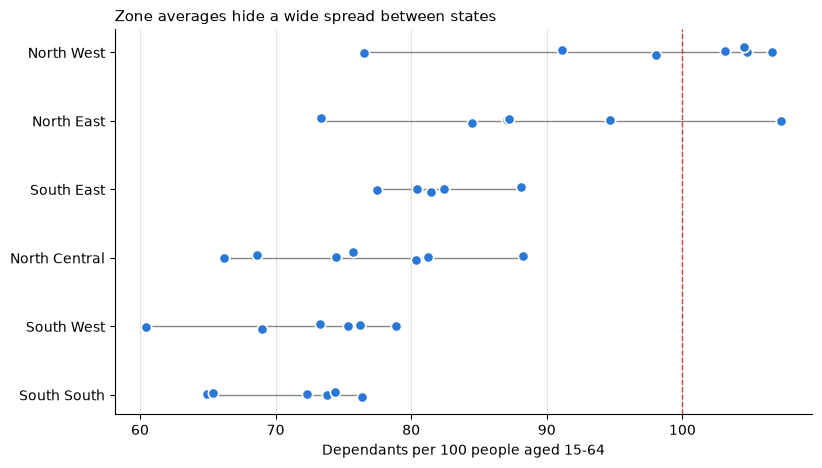

In [11]:
order = (
    states.groupby("zone")["NGA_STATE_DEPENDENCY_RATIO"]
    .median().sort_values().index
)

fig, ax = plt.subplots(figsize=(9, 5))

for position, zone in enumerate(order):
    values = states.loc[
        states["zone"] == zone, "NGA_STATE_DEPENDENCY_RATIO"
    ]
    jitter = np.random.default_rng(0).normal(0, 0.06, len(values))
    ax.scatter(
        values, np.full(len(values), position) + jitter,
        color=BLUE, s=55, edgecolor="white", linewidth=1.2, zorder=3,
    )
    ax.hlines(
        position, values.min(), values.max(),
        color=MUTED, linewidth=1, zorder=2,
    )

ax.axvline(100, color=RED, linewidth=1, linestyle="--")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlabel("Dependants per 100 people aged 15-64")
ax.set_title(
    "Zone averages hide a wide spread between states",
    loc="left", fontsize=11,
)
ax.grid(axis="y", visible=False)
plt.show()

In [12]:
spread = (
    states.groupby("zone")["NGA_STATE_DEPENDENCY_RATIO"]
    .agg(states="count", lowest="min", median="median",
         highest="max")
    .assign(spread=lambda f: f["highest"] - f["lowest"])
    .sort_values("median", ascending=False)
    .round(1)
)
spread

,states,lowest,median,highest,spread
zone,,,,,
North West,7,76.5,103.1,106.6,30.1
North East,6,73.4,87.1,107.2,33.9
South East,5,77.5,81.5,88.1,10.6
North Central,7,66.2,75.7,88.2,22.1
South West,6,60.5,74.3,78.9,18.4
South South,6,64.9,73.0,76.4,11.4


The **North West** has by far the highest median — 103 against 87 for
the next zone — with five of its seven states carrying more than 98
dependants per 100 working-age people. Kaduna, at 77, is a marked
outlier inside its own zone.

The **North East is the widest**, spanning 34 points from Borno (73) to
Bauchi (107): one zone covering most of the national range. Treating
either zone as a single planning unit would be a mistake, and the
national figure more so.

A caution on Borno specifically: it has been the centre of a long
insurgency with large-scale displacement. A population projection
carried forward from the 2006 census reflects that imperfectly, so its
position here should not be read as a straightforward demographic fact.

## 7. What this establishes

- The warehouse separates measured from modelled data, so analysis can
  respect the distinction automatically rather than by convention.
- The national series are I(1). Relationships between them must be
  estimated in changes, not levels; published analyses that regress
  levels of Nigerian macro series should be read sceptically.
- Inflation and per-capita income growth are negatively associated
  (r = -0.38, n = 34). That is a stylised fact, not a causal finding.
- State age structure varies widely *within* zones, so neither the
  national figure nor the zone average describes any particular state
  well.

**The main gap remains state-level economic data.** The NBS publishes
state GDP, poverty and unemployment as PDF reports rather than in
machine-readable form. Until that is extracted, the state layer can
describe who lives where and at what age, but not what they earn or
produce.